In [26]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# hが小さすぎる
def numerical_diff_1(f, x):
    h = 1e-50
    return f(x + h) - f(x) / h


# 前方差分になっている
def numerical_diff_2(f, x):
    h = 1e-4
    return (f(x + h) - f(x)) / h


# 良い実装。
#
def numerical_diff(f, x):
    h = 1e-4
    return (f(x + h) - f(x - h)) / (2 * h)


def func(x):
    return x**2

正しい答えは4だが、計算方法によって異なる答えが算出される

In [24]:
print(numerical_diff_1(func, 2))
print(numerical_diff_2(func, 2))
print(numerical_diff(func, 2))

-4e+50
4.0001000000078335
4.000000000004


下記のようにあまりに小さいと丸めて0になってしまう

In [17]:
print(2 + 1e-50)
print(2 + 1e-4)
np.float32(1e-50)

2.0
2.0001


np.float32(0.0)

In [25]:
def function_1(x):
    return 0.01 * x**2 + 0.1 * x

In [ ]:
def tangent_line(f, x):
    d = numerical_diff(f, x)
    print(f"傾き:{d}")
    # 見やすいように引数をtにしている
    return lambda t: d * (t - x) + f(x)

傾き:0.1999999999990898


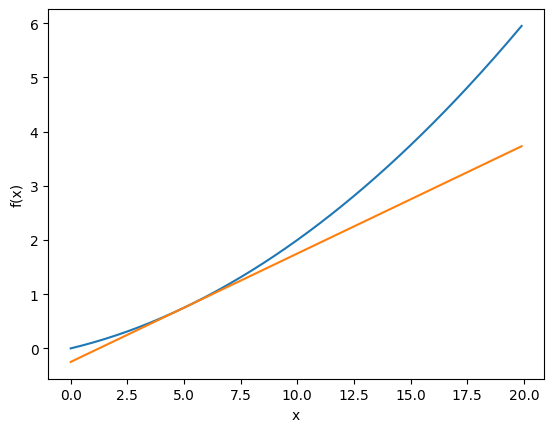

In [33]:
x = np.arange(0.0, 20.0, 0.1)
y = function_1(x)
plt.xlabel("x")
plt.ylabel("f(x)")

# tfは関数であることに注意
tf = tangent_line(function_1, 5)
y2 = tf(x)

plt.plot(x, y)
plt.plot(x, y2)
plt.show()

0.2999999999986347


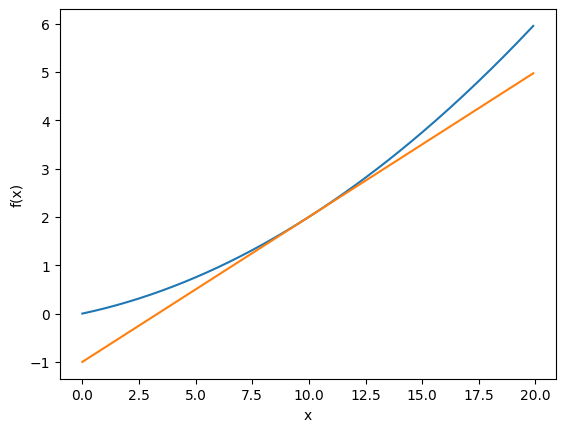

In [29]:
x = np.arange(0.0, 20.0, 0.1)
y = function_1(x)
plt.xlabel("x")
plt.ylabel("f(x)")

tf = tangent_line(function_1, 10)
y2 = tf(x)

plt.plot(x, y)
plt.plot(x, y2)
plt.show()

# 多変数関数

In [ ]:
def function_2(x):
    return x[0] ** 2 + x[1] ** 2

In [ ]:
# (3,4)の時のx0偏微分


def function_tmp0(x0):
    return x0**2 + 4.0**2.0  # x1=4は関数の中で固定してしまう


numerical_diff(function_tmp0, 3)

6.00000000000378

In [ ]:
# (3,4)の時のx1偏微分


def function_tmp1(x1):
    return 3.0**2.0 + x1**2.0  # x0=3は関数の中で固定してしまう


numerical_diff(function_tmp1, 4)

7.999999999999119

In [53]:
def numerical_gradient(f, x):
    h = 1e-4
    # 関数の変数の個数分の次元を持つ空配列を用意する
    grad = np.zeros_like(x)

    # 変数の個数だけ繰り返す
    for idx in range(x.size):
        tmp_val = x[idx]
        # 注目しているindexの要素のみhを加えたものに置き換える
        x[idx] = tmp_val + h
        # print(f"{idx}番目の変数についてhを加えたもの{x}")
        # 注目indexのみ上書きした配列xを代入することでf(x+h)の計算
        fxh1 = f(x)

        x[idx] = tmp_val - h
        # print((f"{idx}番目の変数についてhを引いたもの{x}"))
        # f(x-h)の計算
        fxh2 = f(x)

        grad[idx] = (fxh1 - fxh2) / (2 * h)
        # 値を元に戻す
        x[idx] = tmp_val

    return grad

In [ ]:
x = np.array([3.0, 4.0])
numerical_gradient(function_2, x)

0番目の変数についてhを加えたもの[3.0001 4.    ]
0番目の変数についてhを引いたもの[2.9999 4.    ]
1番目の変数についてhを加えたもの[3.     4.0001]
1番目の変数についてhを引いたもの[3.     3.9999]


array([6., 8.])

In [ ]:
def gradient_descent(f, init_x, lr=0.01, step_num=100):
    loss_array = []
    x = init_x
    for i in range(step_num):
        grad = numerical_gradient(f, x)
        # ブロードキャストで全要素が学習係数*編微分係数の値だけ動かされる。
        x -= lr * grad  # ここで現在地xが更新される
        loss_array.append(f(x))
    return x, loss_array

[-6.11110793e-10  8.14814391e-10]


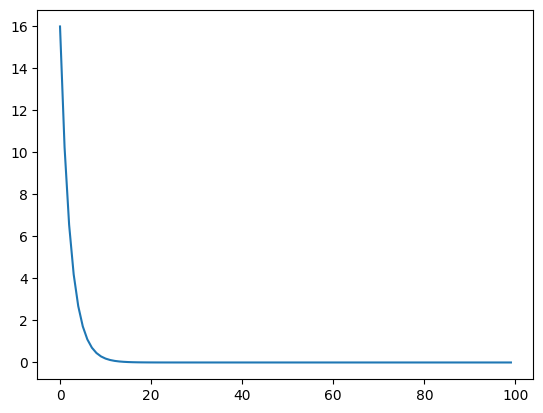

In [ ]:
init_x = np.array([-3.0, 4.0])
ans, array = gradient_descent(function_2, init_x=init_x, lr=0.1, step_num=100)
print(ans)
plt.plot(array)

[-2.58983747e+13 -1.29524862e+12]


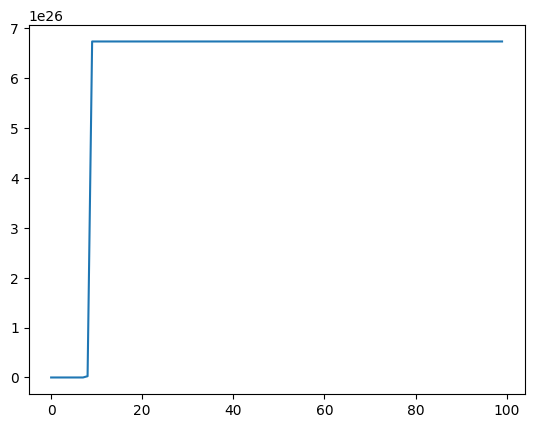

In [ ]:
init_x = np.array([-3.0, 4.0])
ans, array = gradient_descent(function_2, init_x=init_x, lr=10, step_num=100)
print(ans)
plt.plot(array)

[-3.  4.]


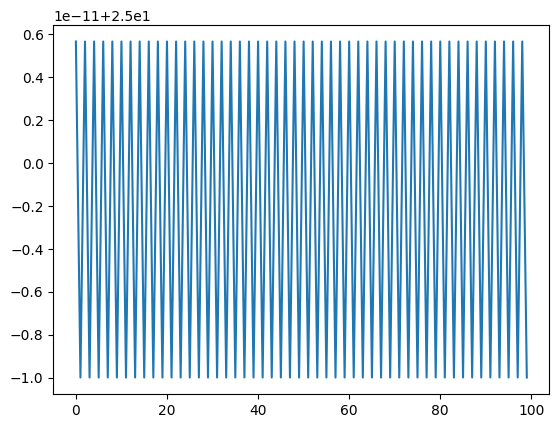

In [ ]:
init_x = np.array([-3.0, 4.0])
ans, array = gradient_descent(function_2, init_x=init_x, lr=1, step_num=100)
print(ans)
plt.plot(array)

[-2.99999994  3.99999992]


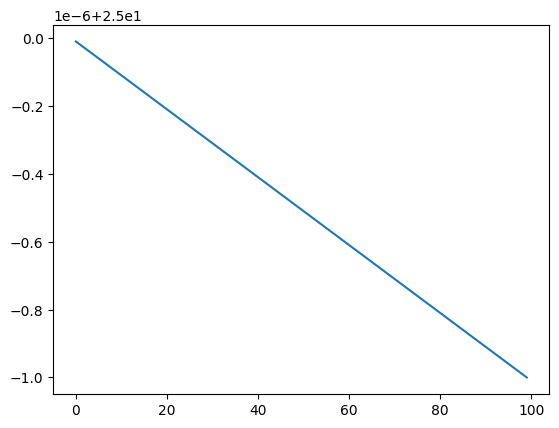

In [ ]:
init_x = np.array([-3.0, 4.0])
ans, array = gradient_descent(function_2, init_x=init_x, lr=1e-10, step_num=100)
print(ans)
plt.plot(array)

In [ ]:
def numerical_gradient(f, x):
    """
    一般の多次元配列に対する数値勾配を求める。
    入力が行列でもテンソルでもそれを多数の独立変数の集まりとして見ている。入力の形式は関数の引数の表記方法なだけで本質的ではないことに注意

    今までは関数の入力がベクトルで、勾配もベクトルの各要素を関数をその要素の変数で微分したものになってたが
    今回は関数の入力が行列でも対応できる。
    勾配も行列orベクトルの各要素を、偏微分に置き換えたものになっている。
    """
    h = 1e-4
    # 関数の変数の個数分の次元を持つ（勾配用の）空配列を用意する
    grad = np.zeros_like(x)

    # np.nditer は、NumPy配列を要素単位で順にたどるためのイテレータ。
    # これを使用しないと入力配列の次元数に応じてその分だけのfor文を回さないといけない
    it = np.nditer(
        x, flags=["multi_index"], op_flags=["readwrite"]
    )  # op_flagsはxの要素を書き換えるため。

    while not it.finished:
        idx = (
            it.multi_index
        )  # 今見ている要素の添え字をタプルとして取得。例えば x が2次元なら idx は (0, 1) みたいなタプルになる。すると x[idx] は x[0, 1] と同じ意味になる。
        tmp_val = x[idx]

        x[idx] = tmp_val + h
        fxh1 = f(x)  # 配列全体を関数に渡している（つまりちゃんと全変数を渡している）

        x[idx] = tmp_val - h
        fxh2 = f(x)  # 配列全体を関数に渡している（つまりちゃんと全変数を渡している）

        grad[idx] = (fxh1 - fxh2) / (2 * h)

        x[idx] = tmp_val

        it.iternext()

    return grad

In [ ]:
def f(x):
    return np.sum(x**2)


x = np.array([[1.0, 2.0], [3.0, 4.0]])

numerical_gradient(f, x)

array([[2., 4.],
       [6., 8.]])

中身確認

In [ ]:
h = 1e-4
# 関数の変数の個数分の次元を持つ（勾配用の）空配列を用意する
grad = np.zeros_like(x)

# np.nditer は、NumPy配列を要素単位で順にたどるためのイテレータ。
it = np.nditer(
    x, flags=["multi_index"], op_flags=["readwrite"]
)  # op_flagsはxの要素を書き換えるため。

In [76]:
it.finished

False

In [81]:
print(it.multi_index)
x[it.multi_index]

(0, 0)


np.float64(1.0)

In [82]:
it.iternext()
print(it.multi_index)
x[it.multi_index]

(0, 1)


np.float64(2.0)